# RD900 reads based analysis

In [1]:
import sys, os, io, csv, glob, subprocess, time, re
import posixpath, urllib, gzip, shutil
from importlib import reload
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import pylab as plt
import seaborn as sns

from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.SeqFeature import SeqFeature, FeatureLocation
from Bio import Entrez

## combine elena data

In [161]:
meta = pd.read_csv('sra_mtbc_animal_reduced.csv',index_col=0)
meta['lineage'] = meta.ScientificName.apply (lambda x:'M. ' + x.split()[-1])
meta['dataset'] = 'Alex'

In [162]:
elena = pd.read_csv('../genomes_data.csv')
elena['dataset'] = 'Elena'
final = pd.concat([meta,elena])
final= final.drop_duplicates('Run')

In [220]:
final.lineage

0             M. marinum
1             M. marinum
2               M. mungi
3              M. orygis
4              M. orygis
             ...        
76    M. tuberculosis L9
77    M. tuberculosis L9
78    M. tuberculosis L9
79                BCG-26
80    M. tuberculosis L6
Name: lineage, Length: 299, dtype: str

In [232]:
def tb_label(s):
    if 'tuberculosis' in s:
        return 'human tb'
    animal=['orygis','bovis','caprae','pinnipedii','mungi','microt','dassie']
    if any(x in s.lower() for x in animal):
        return 'animal adapted'
    return 'other'
    
final['group']=final.lineage.apply(tb_label)

In [233]:
final.to_csv('sra_final.csv',index=False)

In [125]:
def align_reads(df, ref_genome, fastq_dir, outdir):
    print (ref_genome)
    for i, row in df.iterrows():
      # 1. Check if the platform is ILLUMINA
      platform = str(row.get("Platform", "")).strip().upper()
      if platform != "ILLUMINA":
        continue
    
      run_id = row.Run
      
      # File paths (corrected f2 to look for _2.fastq.gz)
      f1 = os.path.join(fastq_dir, f"{run_id}_1.fastq.gz")
      f2 = os.path.join(fastq_dir, f"{run_id}_2.fastq.gz")
      out_bam = os.path.join(outdir, f"{run_id}.bam")
      if os.path.exists(out_bam):
          continue
      if os.path.exists(f1):
        # 2. Check if paired-end (f2 exists) or single-end
        if os.path.exists(f2):
            print(f"-> Paired-end reads detected for {run_id}")
            cmd = (
              f"bwa mem -t {threads} {ref_genome} {f1} {f2} | "
              f"samtools view -b -F 4 - | "  # -F 4 drops unmapped reads here
              f"samtools sort -o {out_bam}"
            )
        else:
          print(f"-> Single-end reads detected for {run_id}")
          cmd = (
              f"bwa mem -t {threads} {ref_genome} {f1} | "
              f"samtools view -b -F 4 - | "  # -F 4 drops unmapped reads here
              f"samtools sort -o {out_bam}"
          )
        subprocess.check_output(cmd, shell=True, stderr=subprocess.STDOUT)
    return

# RD900 simpler analysis using locus only

## align reads

In [ ]:
## align reads to genome so we can extract locus after
outdir = 'aligned_locus'
threads = 12
align_reads(strat, 'RD900MAF.fa', 'read_data', outdir)

In [216]:
elena['Platform']='ILLUMINA'
align_reads(elena, 'RD900MAF.fa', 'elena_data', outdir)

RD900MAF.fa
-> Paired-end reads detected for ERR713575
-> Paired-end reads detected for SRR10828835
-> Paired-end reads detected for SRR1173284
-> Paired-end reads detected for ERR181314
-> Paired-end reads detected for ERR181315
-> Paired-end reads detected for ERR4192383
-> Paired-end reads detected for ERR4192404
-> Paired-end reads detected for ERR4192405
-> Paired-end reads detected for ERR4192384
-> Paired-end reads detected for ERR4162024
-> Paired-end reads detected for SRR3647355
-> Paired-end reads detected for ERR234151


## get coverage in bins

In [189]:
import pysam 

import os
import pysam
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d

def check_bam_index(bam_path):
    """Checks if a BAM index exists. If not, attempts to index it using pysam."""
    index_path = bam_path + ".bai"
    alt_index_path = bam_path.replace(".bam", ".bai")
    
    if not (os.path.exists(index_path) or os.path.exists(alt_index_path)):
        #print(f"Index not found for {bam_path}. Attempting to index with pysam...")
        try:
            pysam.index(bam_path)
        except Exception as e:
            raise RuntimeError(
                f"BAM file {bam_path} is not indexed and automatic indexing failed: {e}. "
                f"Please index it manually using 'samtools index {bam_path}'."
            )

def compute_binned_coverage(bam_files, chrom, bin_size=1000, start=0, end=None, normalize=True):
    """
    Computes binned coverage across a genomic region for multiple BAM files.
    """
    matrix_data = []
    sample_names = []

    # Ensure all BAM files are indexed before proceeding
    for bam_path in bam_files:
        check_bam_index(bam_path)

    # Determine region length using the first BAM file header
    with pysam.AlignmentFile(bam_files[0], "rb") as bam:
        chrom_len = bam.get_reference_length(chrom)
    
    if end is None:
        end = chrom_len
        
    region_len = end - start
    n_bins = region_len // bin_size
    trimmed_len = n_bins * bin_size  

    for bam_path in bam_files:
        sample_name = os.path.basename(bam_path).replace(".bam", "")
        sample_names.append(sample_name)
        
        cov_array = np.zeros(region_len, dtype=np.float32)
        total_mapped = 0
        
        with pysam.AlignmentFile(bam_path, "rb") as bam:
            if normalize:
                stats = bam.get_index_statistics()
                total_mapped = sum(s.mapped for s in stats)
            
            for pileupcolumn in bam.pileup(chrom, start, end, stepper="all"):
                pos = pileupcolumn.pos
                if start <= pos < end:
                    cov_array[pos - start] = pileupcolumn.n
                    
        if normalize and total_mapped > 0:
            scaling_factor = 1e6 / total_mapped
            cov_array *= scaling_factor

        binned = cov_array[:trimmed_len].reshape(n_bins, bin_size).mean(axis=1)
        matrix_data.append(binned)
        
    bin_coords = [start + (i * bin_size) for i in range(n_bins)]
    df = pd.DataFrame(matrix_data, index=sample_names, columns=bin_coords)    
    return df

def apply_gc_correction(df, reference_fasta, chrom, bin_size=1000, start=0):
    """
    Optional function to correct coverage bias based on bin GC content.
    """
    corrected_df = df.copy()
    
    # Extract GC content for each bin from the reference FASTA
    with pysam.FastaFile(reference_fasta) as fasta:
        chrom_seq = fasta.fetch(chrom)
        
    gc_contents = []
    n_bins = df.shape[1]
    
    for i in range(n_bins):
        bin_start = start + (i * bin_size)
        bin_end = bin_start + bin_size
        subseq = chrom_seq[bin_start:bin_end].upper()
        
        g_count = subseq.count('G')
        c_count = subseq.count('C')
        gc_fraction = (g_count + c_count) / len(subseq) if len(subseq) > 0 else 0
        gc_contents.append(round(gc_fraction, 4))
        
    gc_series = pd.Series(gc_contents, index=df.columns)
    
    # Correct each sample based on its GC-coverage relationship
    for sample in corrected_df.index:
        sample_cov = corrected_df.loc[sample]
        
        # Group bins into GC bins (e.g., rounded to 2 decimal places)
        temp_df = pd.DataFrame({'cov': sample_cov, 'gc': gc_series})
        global_median = temp_df['cov'].median()
        
        # Calculate median coverage per GC content level
        gc_medians = temp_df.groupby('gc')['cov'].median()
        
        # Map correction factor: global_median / gc_median
        correction_factors = gc_medians.apply(lambda x: global_median / x if x > 0 else 1.0)
        
        # Apply correction back to bins
        temp_df['correction'] = temp_df['gc'].map(correction_factors)
        corrected_df.loc[sample] = temp_df['cov'] * temp_df['correction']
        
    return corrected_df

def normalize_coverage_matrix(coverage_df, method='median'):
    """
    Normalizes a coverage matrix per sample (row-wise) to remove depth biases 
    between sequencing runs.
    
    Parameters:
    - coverage_df (pd.DataFrame): Rows = samples, Columns = genomic bins.
    - method (str): 
        - 'median' (Recommended for CNV/deletions): Divides each sample by its median 
          coverage. Normal regions ~ 1.0, deletions approach 0.0.
        - 'mean': Divides each sample by its mean coverage.
        - 'minmax': Scales each sample strictly between 0.0 and 1.0.
        
    Returns:
    - pd.DataFrame: Row-normalized coverage matrix.
    """
    norm_df = coverage_df.copy()
    
    if method == 'median':
        # Divide each row by its median coverage
        medians = norm_df.median(axis=1)
        medians[medians == 0] = 1.0  # Prevent division by zero if a sample is totally empty
        norm_df = norm_df.div(medians, axis=0)
        
    elif method == 'mean':
        # Divide each row by its mean coverage
        means = norm_df.mean(axis=1)
        means[means == 0] = 1.0
        norm_df = norm_df.div(means, axis=0)
        
    elif method == 'minmax':
        # Scale each row strictly between 0.0 and 1.0
        row_min = norm_df.min(axis=1)
        row_max = norm_df.max(axis=1)
        row_range = row_max - row_min
        row_range[row_range == 0] = 1.0  # Prevent division by zero if coverage is flat
        norm_df = norm_df.subtract(row_min, axis=0).div(row_range, axis=0)
        
    else:
        raise ValueError("Unknown normalization method. Choose 'median', 'mean', or 'minmax'.")
        
    return norm_df


In [76]:
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster

def get_representative_samples(coverage_df, threshold=0.5, metric='correlation', method='average'):
    """
    Reduces a coverage matrix by clustering samples and picking a representative 
    sample (medoid) for each cluster at a given distance threshold.
    """
    # 0. Sanitize the dataframe: replace inf/-inf with NaN, then fill NaN with 0
    coverage_df = coverage_df.replace([np.inf, -np.inf], np.nan).fillna(0.0)

    if len(coverage_df) <= 1:
        print("Coverage DataFrame has 1 or fewer samples. No clustering needed.")
        assignment_df = pd.DataFrame({
            'Sample': coverage_df.index, 
            'Cluster': 1, 
            'Representative': True
        })
        return coverage_df, assignment_df

    # 1. Compute pairwise distances
    dist_vector = pdist(coverage_df.values, metric=metric)
    
    # Handle any remaining NaNs in the distance vector (e.g., zero-variance rows with correlation metric)
    if np.isnan(dist_vector).any():
        print("Warning: NaN values found in distance matrix (likely due to zero-variance coverage profiles). Filling with 0.0 distance.")
        dist_vector = np.nan_to_num(dist_vector, nan=0.0)

    # 2. Hierarchical linkage and tree cutting
    Z = linkage(dist_vector, method=method)
    clusters = fcluster(Z, t=threshold, criterion='distance')
    
    assignment_df = pd.DataFrame({
        'Sample': coverage_df.index,
        'Cluster': clusters
    })
    
    # 3. Find the medoid (representative sample) for each cluster
    dist_matrix = squareform(dist_vector)
    rep_samples = []
    
    for cluster_id in np.unique(clusters):
        cluster_members = assignment_df[assignment_df['Cluster'] == cluster_id]['Sample'].values
        
        if len(cluster_members) == 1:
            rep_samples.append(cluster_members[0])
        else:
            sub_indices = [coverage_df.index.get_loc(m) for m in cluster_members]
            sub_dist = dist_matrix[np.ix_(sub_indices, sub_indices)]
            mean_dists = sub_dist.sum(axis=1)
            best_idx = sub_indices[np.argmin(mean_dists)]
            rep_samples.append(coverage_df.index[best_idx])
            
    assignment_df['Representative'] = assignment_df['Sample'].isin(rep_samples)
    reduced_df = coverage_df.loc[rep_samples]
    
    return reduced_df, assignment_df
    

In [250]:
from dna_features_viewer import GraphicRecord, GraphicFeature

from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, leaves_list
import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle

def plot_matrix(df, meta, leg_cols):
    """
    Plots a clustermap of the coverage matrix with one or more categorical 
    annotation sidebars and a clean standard legend.
    
    Parameters:
    - df (pd.DataFrame): Coverage matrix (rows = samples, columns = bins).
    - meta (df.DataFrame): Metadata table containing a 'Run' column.
    - leg_cols (str or list): Column name(s) in meta to use for row color sidebars.
    """
    import matplotlib.patches as mpatches
    # Ensure leg_cols is always treated as a list
    if isinstance(leg_cols, str):
        leg_cols = [leg_cols]
        
    # Re-index metadata to match the exact row order of your coverage matrix
    meta_sorted = meta.set_index("Run").loc[df.index]
    
    row_colors_dict = {}
    legend_handles = []
    
    # Different color palettes to cycle through if using multiple columns
    palettes = ["tab20", "Set2", "Dark2", "Accent"]
    
    for i, col in enumerate(leg_cols):
        cat_list = meta_sorted[col]
        unique_cats = cat_list.unique()
        
        # Pick a distinct palette for each metadata column
        palette_name = palettes[i % len(palettes)]
        palette = sns.color_palette(palette_name, len(unique_cats))
        cat_to_color = dict(zip(unique_cats, palette))
        
        # Map categories to colors for the clustermap sidebar dataframe
        row_colors_dict[col] = cat_list.map(cat_to_color)
        
        # Build legend patches with a header for each metadata category type
        legend_handles.append(mpatches.Patch(color='none', label=f'[{col}]'))
        for cat, color in cat_to_color.items():
            legend_handles.append(mpatches.Patch(color=color, label=str(cat)))
            
    # Combine individual series into a DataFrame for multi-sidebar support in Seaborn
    row_colors_df = pd.DataFrame(row_colors_dict, index=df.index)
    
    # --- Plot the Seaborn Clustermap ---
    g = sns.clustermap(
        df,
        row_colors=row_colors_df,   # Supports single or multiple columns
        yticklabels=False,          # Set to True or custom labels if preferred
        xticklabels=False,          # Hide crowded genomic bin tick labels
        cmap="Blues",               # Choose your preferred colormap
        figsize=(12, 8),
        col_cluster=False,       # Keep column clustering off for sequential genomic bins
        cbar_pos=None
    )
    
    # --- Add a Clean Standard Legend ---
    # Place the legend cleanly outside the plot area on the right
    g.fig.legend(
        handles=legend_handles,
        bbox_to_anchor=(1.02, 0.85),
        loc='upper left',
        borderaxespad=0.,
        frameon=True,
        fontsize=9
    )
    return g

def plot_heatmap_with_features(df, meta, lineage_col, gff_path, chrom, start, end):
    """
    Plots a single-panel coverage heatmap with multi-colored feature blocks 
    drawn below it, with feature names displayed directly inside the blocks.
    """
    # 1. Re-index and sort metadata and coverage matrix by lineage
    meta_sorted = meta.set_index("Run").loc[df.index]
    meta_sorted = meta_sorted.sort_values(by=lineage_col)
    df_sorted = df.loc[meta_sorted.index]
    
    n_samples = len(df_sorted)
    
    # 2. Set up figure
    fig, ax = plt.subplots(figsize=(14, 9))
    
    # --- Coordinate-Aligned Heatmap (imshow) ---
    im = ax.imshow(
        df_sorted.values,
        aspect='auto',
        extent=[start, end, n_samples, 0],
        cmap="Blues"
    )
    
    # Format Y-axis for samples
    ax.set_yticks(np.arange(n_samples) + 0.5)
    custom_yticklabels = [f"{run} ({meta_sorted.loc[run, lineage_col]})" for run in df_sorted.index]
    ax.set_yticklabels(custom_yticklabels, fontsize=9)
    ax.set_ylabel("Samples (Sorted by Lineage)", fontsize=10)
    ax.set_title(f"Coverage Heatmap & Feature Annotations: {chrom}:{start}-{end}", fontsize=12, pad=15)
    
    # Add colorbar
    fig.colorbar(im, ax=ax, label='Normalized Coverage', fraction=0.02, pad=0.04)
    
    # --- Parse GFF and Draw Distinctly Colored Feature Blocks ---
    track_y_start = n_samples + 0.2
    track_height = 1.6
    
    # Fallback color palette if GFF doesn't specify a color tag
    fallback_palette = plt.cm.tab20(np.linspace(0, 1, 20))
    color_idx = 0
    
    with open(gff_path, "r") as f:
        for line in f:
            if line.startswith("#") or not line.strip():
                continue
                
            parts = line.strip().split("\t")
            if len(parts) < 9:
                continue
                
            seq_id, source, feat_type, f_start, f_end_str, score, strand, phase, attributes = parts
            
            if seq_id == chrom:
                f_start = int(f_start)
                f_end = int(f_end_str)
                
                # Check overlap with viewing window
                if f_end > start and f_start < end:
                    plot_start = max(start, f_start)
                    plot_end = min(end, f_end)
                    width = plot_end - plot_start
                    
                    # Extract label and check for explicit color attribute in GFF
                    label = feat_type
                    custom_color = None
                    
                    for attr in attributes.split(";"):
                        if "=" in attr:
                            k, v = attr.split("=", 1)
                            k_clean = k.strip().lower()
                            v_clean = v.strip()
                            if k_clean in ["name", "gene", "id"]:
                                label = v_clean
                            elif k_clean == "color":
                                custom_color = v_clean
                                
                    # Assign color (use GFF tag if present, otherwise cycle through fallback palette)
                    if not custom_color:
                        custom_color = fallback_palette[color_idx % len(fallback_palette)]
                        color_idx += 1
                        
                    # Draw rectangle block in the bottom track area
                    rect = Rectangle(
                        (plot_start, track_y_start), 
                        width, track_height, 
                        facecolor=custom_color, 
                        edgecolor="black", 
                        linewidth=0.5, 
                        alpha=0.85
                    )
                    ax.add_patch(rect)
                    
                    # Place the text directly inside the rectangle
                    # Only add text if the block has enough horizontal width
                    if width > (end - start) * 0.01:
                        ax.text(
                            plot_start + (width / 2), 
                            track_y_start + (track_height / 2), 
                            label,
                            ha="center", va="center", fontsize=8, color="black", fontweight="bold",
                            rotation=0  # Keep horizontal or change to 30 if names are long
                        )

    # Extend Y-axis limits downwards to accommodate the feature track
    ax.set_ylim(n_samples + 1.8, 0)
    ax.set_xlim(start, end)
    
    # Clean up X-axis
    ax.set_xlabel(f"Genomic Position ({chrom})", fontsize=10)
    ax.tick_params(labelbottom=True)
    
    plt.tight_layout()    

In [245]:
bam_list = glob.glob('aligned_locus/*.bam')
cov_df = compute_binned_coverage(bam_list, chrom="GM041182", bin_size=30)
cov_df = normalize_coverage_matrix(cov_df, method='median')

reduced, cluster_mapping = get_representative_samples(
     cov_df, 
     threshold=0.1,     # Adjust threshold based on how strict you want the grouping to be
     metric='correlation'
 )
print(f"Reduced from {len(cov_df)} to {len(reduced)} representative samples.")

# 2. Threshold using a fraction (e.g., 0.2 means coverage dropped to 20% or less of baseline)
threshold_fraction = 0.1

# Creates a boolean DataFrame (True where a deletion/drop is suspected)
deletion_mask = reduced > threshold_fraction
# Optional: Convert to 1 (deletion/low) and 0 (normal) for downstream use or plotting
del_df = deletion_mask.astype(int)

# Quick check: count how many bins are flagged as deleted per sample
#print(binary_deletion_matrix.sum(axis=1))
#reduced[reduced<.5]=0
#cov_df[cov_df>10]=1

Reduced from 209 to 118 representative samples.


/home/farrell/.venv/lib/python3.14/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


Text(0.5, 0.98, 'RD900 structure: binned raw read coverage')

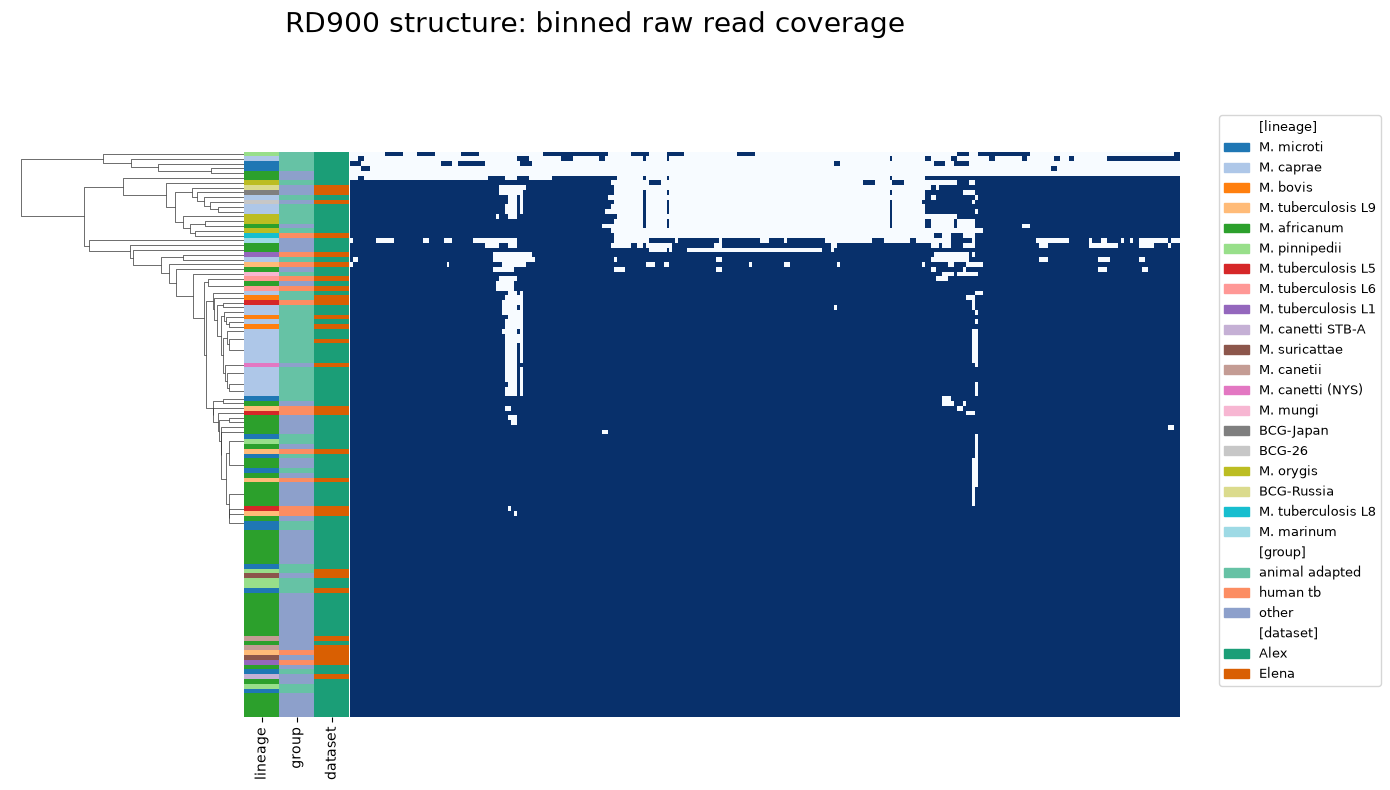

In [246]:
g=plot_matrix(del_df, final, leg_cols=['lineage','group','dataset']) 
g.fig.suptitle('RD900 structure: binned raw read coverage',fontsize=20)

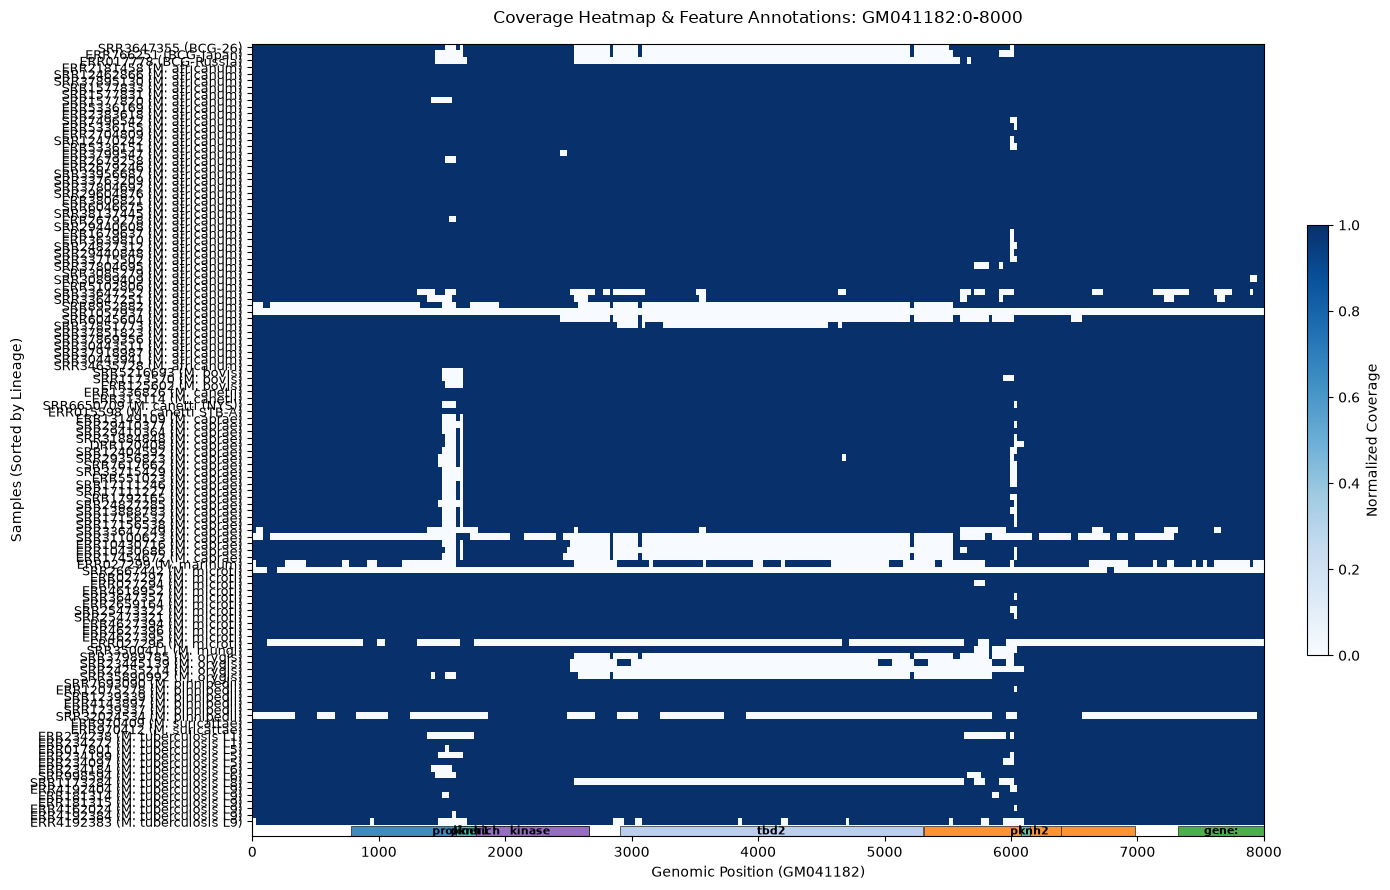

In [251]:
plot_heatmap_with_features(del_df, final, 'lineage', 'RD900MAF.gff', 'GM041182', 0, 8000)

## RD900 more complex analysis using full genome 

Workflow
--------
1. map_reads()           reads -> BAM against the FULL M. africanum GM041182 genome
2. run_mosdepth()        BAM -> binned depth (100 bp by default), once per MAPQ cutoff
3. build_matrix()        binned depth -> normalised samples x bins matrix + QC table
4. summarise_genes()     optional per-gene summary (embR, pknH1, tbd2, pknH2, ...)
5. call_states()         continuous ratios -> 0 absent / 1 reduced / 2 present
6. deletion_table()      per-sample deletion intervals + a genotype string
7. genotype_counts()     collapse hundreds of samples into a handful of patterns
8. plot_heatmap()        clustered heatmap with metadata colour bars and gene labels

Requires on PATH: bwa, minimap2, samtools, mosdepth

In [ ]:
## align reads to genome so we can extract locus after
outdir = 'aligned'
ref_genome = "GM041182.fna" 
threads = 12

In [3]:
import gzip
import shlex
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

LONG_READ_PRESETS = {
    "OXFORD_NANOPORE": "map-ont",
    "PACBIO_SMRT": "map-pb",   # use "map-hifi" instead if the run is HiFi/CCS
}


# ---------------------------------------------------------------
# 1. Mapping (skip if you already have BAMs)
# ---------------------------------------------------------------
def map_reads(ref_fasta, out_bam, fq1, fq2=None, platform="ILLUMINA", threads=8):
    """
    Maps reads to the full reference genome and writes a sorted, indexed BAM.
    Short reads -> bwa mem. Nanopore / PacBio -> minimap2.
    (Run `bwa index ref.fasta` once beforehand for short reads.)
    """
    ref, bam = shlex.quote(str(ref_fasta)), shlex.quote(str(out_bam))
    reads = " ".join(shlex.quote(str(f)) for f in [fq1, fq2] if f)

    if platform in LONG_READ_PRESETS:
        aligner = f"minimap2 -ax {LONG_READ_PRESETS[platform]} -t {threads} {ref} {reads}"
    else:
        aligner = f"bwa mem -t {threads} {ref} {reads}"

    cmd = f"{aligner} | samtools sort -@ {threads} -o {bam} - && samtools index {bam}"
    subprocess.run(cmd, shell=True, check=True, executable="/bin/bash")
    return str(out_bam)


# ---------------------------------------------------------------
# 2. Binned depth with mosdepth
# ---------------------------------------------------------------
def run_mosdepth(bam, out_dir, sample, bin_size=100, mapq=20, threads=4):
    """
    Runs mosdepth with fixed-width bins across the whole genome.
    Call it twice (e.g. mapq=0 and mapq=20) to see how much of the paralog
    zone (pknH1/pknH2) is being driven by multi-mapping reads.
    Returns the path to the <sample>.mq<MAPQ>.regions.bed.gz file.
    """
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    prefix = out_dir / f"{sample}.mq{mapq}"
    cmd = [
        "mosdepth", "--no-per-base",
        "--by", str(bin_size),
        "--mapq", str(mapq),
        "-t", str(threads),
        str(prefix), str(bam),
    ]
    subprocess.run(cmd, check=True)
    return f"{prefix}.regions.bed.gz"


# ---------------------------------------------------------------
# 3. Normalised samples x bins matrix
# ---------------------------------------------------------------
def _read_regions(path):
    with gzip.open(path, "rt") as fh:
        return pd.read_csv(fh, sep="\t", header=None,
                           names=["chrom", "start", "end", "depth"])


def build_matrix(regions_files, chrom, locus_start, locus_end,
                 flank=3000, min_baseline=20):
    """
    regions_files : dict {sample: path to mosdepth .regions.bed.gz}
    chrom         : contig name of the GM041182 reference
    locus_start/end : 0-based coordinates of the RD900 locus on that contig
    flank         : bp of unique flanking sequence to keep on each side
                    (acts as an "always present" control in the heatmap)
    min_baseline  : samples whose genome-wide median depth is below this are
                    flagged in qc['low_depth'] (they are kept, not dropped)

    Each bin's depth is divided by the sample's baseline: the median depth of
    all bins on the contig OUTSIDE locus +/- flank. The median is robust to the
    repeats and duplications in the genome. 1.0 = single-copy-like coverage,
    ~0.5 = one of two paralog copies' worth, ~0 = absent.

    Returns (matrix, qc). matrix index = sample, columns = bin start coord.
    """
    win_start, win_end = locus_start - flank, locus_end + flank
    rows, qc = {}, []

    for sample, path in regions_files.items():
        df = _read_regions(path)
        df = df[df["chrom"] == chrom]

        outside = df[(df["end"] <= win_start) | (df["start"] >= win_end)]
        baseline = outside["depth"].median()

        window = df[(df["end"] > win_start) & (df["start"] < win_end)]
        ratios = window.set_index("start")["depth"] / baseline if baseline > 0 else window.set_index("start")["depth"] * np.nan
        rows[sample] = ratios
        qc.append({"sample": sample, "baseline_depth": baseline,
                   "low_depth": bool(baseline < min_baseline)})

    matrix = pd.DataFrame(rows).T.sort_index(axis=1)
    qc = pd.DataFrame(qc).set_index("sample")
    return matrix, qc


def summarise_genes(matrix, genes, bin_size=100):
    """
    genes : dict {name: (start, end)} on the same coordinates as the matrix,
            taken from the GM041182 GFF, e.g.
            {"embR": (a, b), "pknH1": (c, d), "tbd2": (...), "pknH2": (...)}
    Returns samples x genes of the mean normalised depth over overlapping bins.
    """
    out = {}
    starts = matrix.columns.to_numpy()
    for name, (g_start, g_end) in genes.items():
        mask = (starts < g_end) & (starts + bin_size > g_start)
        out[name] = matrix.loc[:, mask].mean(axis=1)
    return pd.DataFrame(out)


# ---------------------------------------------------------------
# 4. Discrete states + deletion intervals
# ---------------------------------------------------------------
def call_states(matrix, absent_below=0.2, present_above=0.8):
    """
    0 = absent (< absent_below), 2 = present (> present_above),
    1 = reduced / uncertain in between (e.g. one paralog copy remaining).
    Thresholds are starting points - look at the distribution of your own
    ratios before trusting them.
    """
    vals = matrix.to_numpy(dtype=float)
    states = np.select([vals < absent_below, vals > present_above], [0, 2], default=1)
    states = np.where(np.isnan(vals), -1, states)   # -1 = no data
    return pd.DataFrame(states, index=matrix.index, columns=matrix.columns)


def _runs(positions, mask, bin_size, min_bins):
    """Contiguous runs of True in mask -> list of (start, end) coordinates."""
    runs, run_start, prev = [], None, None
    for pos, flag in zip(positions, mask):
        if flag and run_start is None:
            run_start = pos
        if not flag and run_start is not None:
            if (prev - run_start) // bin_size + 1 >= min_bins:
                runs.append((int(run_start), int(prev + bin_size)))
            run_start = None
        prev = pos
    if run_start is not None and (prev - run_start) // bin_size + 1 >= min_bins:
        runs.append((int(run_start), int(prev + bin_size)))
    return runs


def deletion_table(states, bin_size=100, min_bins=3):
    """
    One row per sample with its absent / reduced intervals and a genotype
    string such as "del:2300-3100|red:3100-3400" ("intact" if none).
    min_bins stops single noisy bins being called as deletions.
    Note: bins are quantised, so deletions whose breakpoints differ by one bin
    get different genotype strings - round the intervals if you want looser
    grouping.
    """
    positions = states.columns.to_numpy()
    records = []
    for sample, row in states.iterrows():
        s = row.to_numpy()
        absent = _runs(positions, s == 0, bin_size, min_bins)
        reduced = _runs(positions, s == 1, bin_size, min_bins)
        parts = [f"del:{a}-{b}" for a, b in absent] + [f"red:{a}-{b}" for a, b in reduced]
        records.append({
            "sample": sample,
            "absent_intervals": absent,
            "reduced_intervals": reduced,
            "n_absent_bins": int((s == 0).sum()),
            "n_reduced_bins": int((s == 1).sum()),
            "genotype": "|".join(parts) if parts else "intact",
        })
    return pd.DataFrame(records).set_index("sample")


def genotype_counts(dtable, meta=None, by=None):
    """
    Counts samples per genotype pattern. Pass meta (DataFrame indexed by
    sample) and by="species" (or any column) to get pattern x group counts.
    Open one representative per pattern in IGV, plus the rare ones.
    """
    if meta is None or by is None:
        return dtable["genotype"].value_counts().to_frame("n_samples")
    joined = dtable.join(meta[[by]], how="left")
    return pd.crosstab(joined["genotype"], joined[by])


# ---------------------------------------------------------------
# 5. Clustered heatmap
# ---------------------------------------------------------------
def plot_heatmap(matrix, meta=None, color_cols=None, genes=None, bin_size=100,
                 vmax=1.5, out_png=None, figsize=(14, 12)):
    """
    Samples (rows, clustered) x bins (columns, kept in genome order).
    meta       : DataFrame indexed by sample (species, BioProject, platform...)
    color_cols : metadata columns to show as row colour bars
    genes      : dict {name: (start, end)} - draws boundaries and labels
    Values are clipped to [0, vmax] so amplifications don't wash out the scale.
    """
    import matplotlib.pyplot as plt
    import seaborn as sns

    data = matrix.fillna(0).clip(lower=0, upper=vmax)

    row_colors = None
    if meta is not None and color_cols:
        bars = {}
        for col in color_cols:
            values = meta.reindex(data.index)[col].fillna("NA").astype(str)
            palette = dict(zip(sorted(values.unique()),
                               sns.color_palette("tab20", values.nunique())))
            bars[col] = values.map(palette)
        row_colors = pd.DataFrame(bars)

    g = sns.clustermap(
        data, row_cluster=True, col_cluster=False,
        cmap="viridis", vmin=0, vmax=vmax,
        row_colors=row_colors, figsize=figsize,
        xticklabels=False, yticklabels=len(data) <= 60,
        cbar_kws={"label": "depth / baseline"},
    )

    if genes:
        ax = g.ax_heatmap
        first = data.columns.min()
        ticks, labels = [], []
        for name, (g_start, g_end) in genes.items():
            lo = (g_start - first) / bin_size
            hi = (g_end - first) / bin_size
            ax.axvline(lo, color="white", lw=0.6, ls="--")
            ax.axvline(hi, color="white", lw=0.6, ls="--")
            ticks.append((lo + hi) / 2)
            labels.append(name)
        ax.set_xticks(ticks)
        ax.set_xticklabels(labels, rotation=90, fontsize=8)

    if out_png:
        g.savefig(out_png, dpi=200, bbox_inches="tight")
    return g

In [ ]:

# ---------------------------------------------------------------
# Example usage
# ---------------------------------------------------------------
# chrom = "NC_xxxxxx.1"               # contig name in your GM041182 fasta
# locus = (1234567, 1237708)          # RD900 start/end on that contig (~3.1 kb)
# genes = {"embR": (...), "pknH1": (...), "tbd2": (...), "pknH2": (...), "MAF_RS06695": (...)}
#
# files_q20 = {s: run_mosdepth(bam, "cov", s, mapq=20) for s, bam in bams.items()}
# matrix, qc = build_matrix(files_q20, chrom, *locus, flank=3000)
# matrix = matrix.loc[~qc["low_depth"]]
#
# states = call_states(matrix)
# dtable = deletion_table(states)
# print(genotype_counts(dtable, meta, by="ScientificName"))
# plot_heatmap(matrix, meta, color_cols=["ScientificName", "BioProject", "Platform"],
#              genes=genes, out_png="rd900_heatmap.png")


## mosdepth

In [ ]:
chrom = "FR878060.1"               # contig name in reference
locus = (1411867,1421648)     # RD900 start/end on that contig (~3.1 kb)
genes = {"embR": (...), "pknH1": (...), "tbd2": (...), "pknH2": (...), "MAF_RS06695": (...)}

bams = glob.glob('aligned/*.bam')
files_q20 = {s: run_mosdepth(bam, "cov", s, mapq=20) for s, bam in bams.items()}


In [ ]:
#matrix, qc = build_matrix(files_q20, chrom, *locus, flank=3000)
#matrix = matrix.loc[~qc["low_depth"]]
#
# states = call_states(matrix)
# dtable = deletion_table(states)
# print(genotype_counts(dtable, meta, by="ScientificName"))
# plot_heatmap(matrix, meta, color_cols=["ScientificName", "BioProject", "Platform"],
#              genes=genes, out_png="rd900_heatmap.png")